# Globális lakásvásárlási döntés — bináris klasszifikáció

## Cél és kérdés

Ebben a notebookban azt vizsgáljuk, hogy a lakás, a környék és a vevő pénzügyi
adatai alapján előre jelezhető-e a `decision` változó értéke. A pozitív osztály
(`decision = 1`) azt jelenti, hogy a megfigyelés a pozitív döntési kategóriába
tartozik; a konkrét üzleti jelentést a Kaggle-adatleírás alapján kell kezelni,
mert az adat nem tartalmaz részletes döntési szótárt.

A cél nem egyetlen magas pontszám elérése, hanem egy szivárgásmentes,
érthető modell-összehasonlítás. A hamis pozitív és a hamis negatív hiba költsége
nincs számszerűsítve, ezért a rangsorolási képességet (`PR-AUC`) és a két osztály
kiegyensúlyozott felismerését (`balanced accuracy`) előre választjuk fő
mutatónak. A küszöböt később a tanító adatokból, üzleti költség hiányában a
balanced accuracy maximuma alapján választjuk ki.


In [2]:
from pathlib import Path
import warnings

import matplotlib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DATA_CANDIDATES = [
    Path("global_house_purchase_dataset_clean.csv"),
    Path("4. órai házik") / "klasszifikátor - Random Forest (frissített)" / "global_house_purchase_dataset_clean.csv",
]
DATA_PATH = next((candidate for candidate in DATA_CANDIDATES if candidate.exists()), None)
assert DATA_PATH is not None, "Nem található a global_house_purchase_dataset_clean.csv adatfájl."

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")


## Útmutató

Ez a notebook két dolgot csinál:

1. megtanít és tisztességesen kiértékel egy modellt;
2. a végén lehetővé teszi, hogy saját lakásadatot adj meg, és a modell megbecsülje
   a `decision` értékét.

A notebookban a kódcellák után mindig keresd a táblázatokat, a számokat és az
ábrákat. Ezekből látjuk, hogy mit tanult a modell. A cél nem egyetlen szép szám
elérése, hanem annak megértése, hogy az eredmény mikor megbízható és mikor kell
óvatosan értelmezni.

**Fontos:** a `decision = 1` a pozitív osztály. A dataset nem magyarázza meg
részletesen, hogy ez milyen valós üzleti döntést jelent, ezért a notebookban
előrejelzésként kezeljük, nem biztos válaszként.

## 1. Az adatok megismerése: EDA

Az EDA (feltáró adatelemzés) azt jelenti, hogy még modellépítés előtt
megnézzük az adatokat. Ilyenkor ezekre a kérdésekre válaszolunk:

- hány sor és oszlop van;
- milyen típusú változóink vannak;
- van-e hiányzó vagy duplikált adat;
- mennyire gyakori a két célkategória;
- mely változók között látszik érdekes kapcsolat.

Az ábrák nem önmagukban jelentik a választ. Segítenek hipotéziseket alkotni,
amelyeket később a modell és a validáció ellenőriz.

## 1. Nyers adat, célváltozó és EDA

A célváltozó vizsgálatakor külön figyelünk azokra a változókra, amelyek túl tökéletes kapcsolatot mutatnak a céllal.

In [6]:
df = pd.read_csv(DATA_PATH, sep=";")
ratio_raw = df["emi_to_income_ratio"].astype("string")
ratio_numeric = pd.to_numeric(ratio_raw, errors="coerce")
excel_date_mask = ratio_numeric.isna() & ratio_raw.str.match(r"^\d{1,2}\.", na=False)
ratio_numeric.loc[excel_date_mask] = (
    ratio_raw.loc[excel_date_mask].str.extract(r"^(\d{1,2})\.")[0].astype(float) / 100
)
if ratio_numeric.isna().any():
    bad_values = ratio_raw.loc[ratio_numeric.isna()].unique().tolist()
    raise ValueError(f"Nem értelmezhető emi_to_income_ratio értékek: {bad_values[:10]}")
df["emi_to_income_ratio"] = ratio_numeric

print(f"Méret: {df.shape[0]:,} sor × {df.shape[1]} oszlop")
display(df.head())
display(df.dtypes.to_frame("dtype"))


Méret: 200,000 sor × 25 oszlop


,property_id,country,city,property_type,furnishing_status,property_size_sqft,price,constructed_year,previous_owners,rooms,bathrooms,garage,garden,crime_cases_reported,legal_cases_on_property,customer_salary,loan_amount,loan_tenure_years,monthly_expenses,down_payment,emi_to_income_ratio,satisfaction_score,neighbourhood_rating,connectivity_score,decision
0,1,France,Marseille,Farmhouse,Semi-Furnished,991,412935,1989,6,6,2,1,1,1,0,10745,193949,15,6545,218986,0.16,1,5,6,0
1,2,South Africa,Cape Town,Apartment,Semi-Furnished,1244,224538,1990,4,8,8,1,1,1,1,16970,181465,20,8605,43073,0.08,9,1,2,0
2,3,South Africa,Johannesburg,Farmhouse,Semi-Furnished,4152,745104,2019,5,2,1,1,1,0,0,21914,307953,30,2510,437151,0.09,6,8,1,0
3,4,Germany,Frankfurt,Farmhouse,Semi-Furnished,3714,1110959,2008,1,3,3,0,1,0,0,17980,674720,15,8805,436239,0.33,2,6,6,0
4,5,South Africa,Johannesburg,Townhouse,Fully-Furnished,531,99041,2007,6,3,3,1,1,3,1,17676,65833,25,8965,33208,0.03,3,3,4,0


,dtype
property_id,int64
country,str
city,str
property_type,str
furnishing_status,str
property_size_sqft,int64
price,int64
constructed_year,int64
previous_owners,int64
rooms,int64


In [7]:
missing = df.isna().sum().sort_values(ascending=False)
duplicates = df.duplicated().sum()
target_counts = df["decision"].value_counts().sort_index()
target_rate = df["decision"].mean()

print("Hiányzó értékek:")
display(missing[missing > 0].to_frame("missing_count"))
print(f"Teljesen duplikált sorok: {duplicates:,}")
print(f"Pozitív osztály aránya: {target_rate:.1%}")
display(target_counts.rename(index={0: "decision=0", 1: "decision=1"}).to_frame("count"))
print("Célváltozó-ellenőrzés: néhány bemeneti változó erős szabályos kapcsolatot mutat.")
display(
    df.groupby(["legal_cases_on_property", "satisfaction_score"], observed=True)["decision"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "positive_rate"})
    .tail(10)
)


Hiányzó értékek:
Teljesen duplikált sorok: 0
Pozitív osztály aránya: 23.0%
Célváltozó-ellenőrzés: néhány bemeneti változó erős szabályos kapcsolatot mutat.


,missing_count


,count
decision,
decision=0,153932
decision=1,46068


positive_rate  count
legal_cases_on_property satisfaction_score                      
1                       1                             0.0   5082
                        2                             0.0   4992
                        3                             0.0   5012
                        4                             0.0   4867
                        5                             0.0   5000
                        6                             0.0   5043
                        7                             0.0   4965
                        8                             0.0   4961
                        9                             0.0   4946
                        10                            0.0   4916

### EDA-megfigyelések és hipotézisek

1. A célváltozó aránya nem teljesen kiegyensúlyozott, ezért a nyers accuracy
   félrevezető lehet.
2. A `price`, `loan_amount`, `down_payment` és `customer_salary` együtt
   pénzügyi terheltséget jelezhetnek; ezért a hányadosok informatívabbak
   lehetnek, mint az egyes változók külön-külön.
3. A `satisfaction_score`, `neighbourhood_rating` és `connectivity_score`
   magasabb értékei összefügghetnek a pozitív döntéssel.
4. A kategóriák (`country`, `city`, `property_type`, `furnishing_status`)
   eltérő csoportkockázatokat rejthetnek, ezért one-hot kódolást használunk.


### Hogyan olvasd az első három ábrát?

Az első rész a célváltozó arányát mutatja. Ha a két kategória nem egyformán
gyakori, a nyers accuracy félrevezető lehet. A dobozdiagramoknál a középső
vonal a medián, a doboz a középső 50% értéke. A két döntési osztály eloszlását
hasonlítjuk össze az ár és az EMI/jövedelem arány esetén.

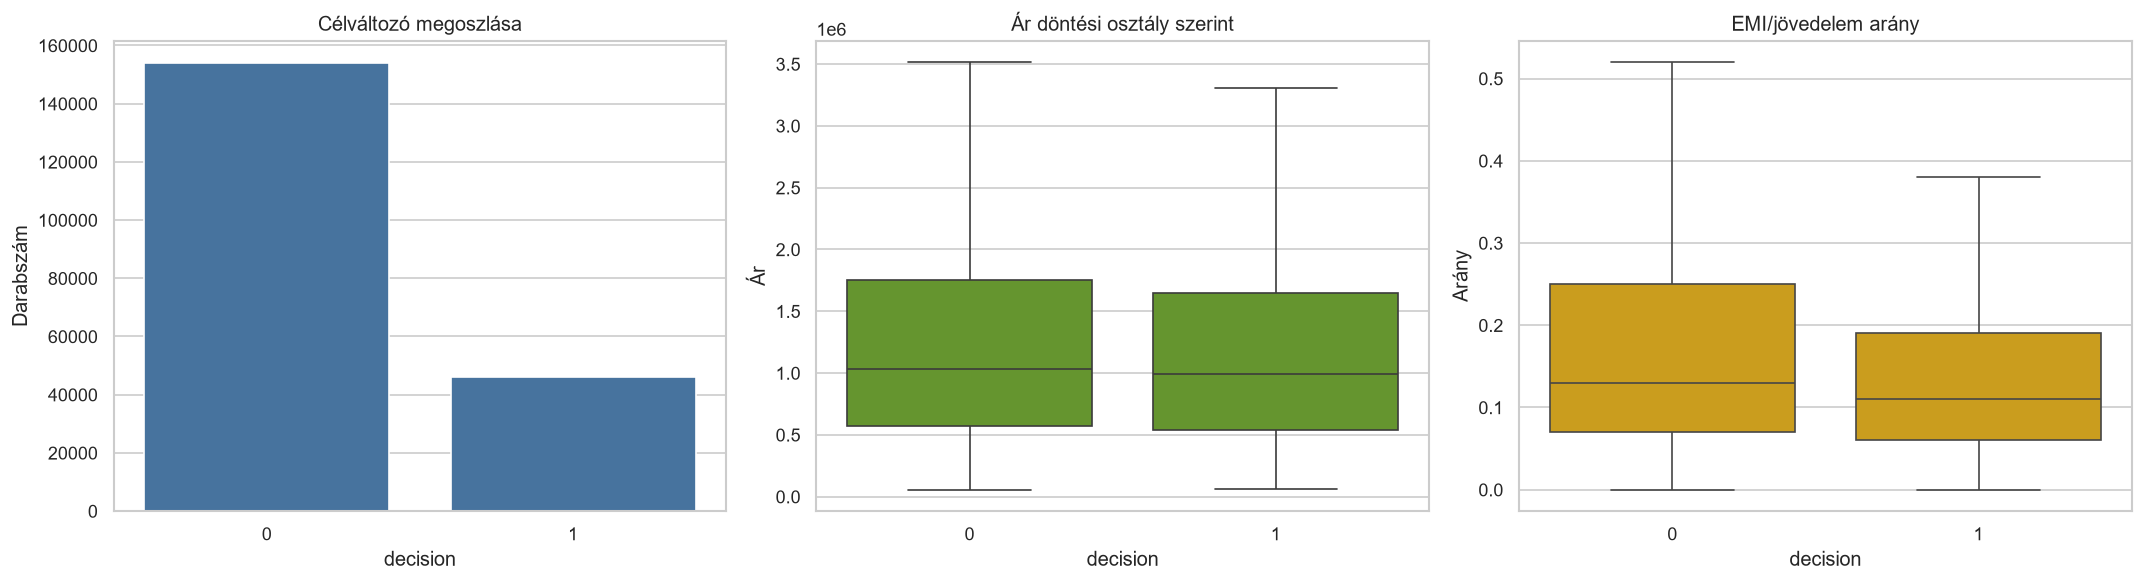

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df, x="decision", ax=axes[0], color="#3973ac")
axes[0].set_title("Célváltozó megoszlása")
axes[0].set_xlabel("decision")
axes[0].set_ylabel("Darabszám")

sns.boxplot(data=df, x="decision", y="price", showfliers=False, ax=axes[1], color="#66a61e")
axes[1].set_title("Ár döntési osztály szerint")
axes[1].set_ylabel("Ár")

sns.boxplot(data=df, x="decision", y="emi_to_income_ratio", showfliers=False, ax=axes[2], color="#e6ab02")
axes[2].set_title("EMI/jövedelem arány")
axes[2].set_ylabel("Arány")

plt.tight_layout()
plt.show()


**Értelmezés:** ha a két döntési osztály eloszlása erősen eltér, az adott
változó hasznos lehet a modell számára. Ez azonban nem bizonyít ok-okozati
kapcsolatot.

### 2. ábra: országonkénti pozitív arány

A színes oszlopok az egyes országokban mért `decision = 1` arányt mutatják.
A szaggatott vonal a teljes adatállomány átlagos pozitív aránya. Az ábra
indokolhatja a `country` változó megtartását, de nem bizonyít ok-okozati
kapcsolatot.

,positive_rate,count
country,,
Germany,0.264668,15408
Australia,0.261689,15442
China,0.258175,15536
Canada,0.257061,15401
UK,0.254720,15413
France,0.248848,15628
Japan,0.245544,15317
UAE,0.233406,15141
India,0.217686,15357


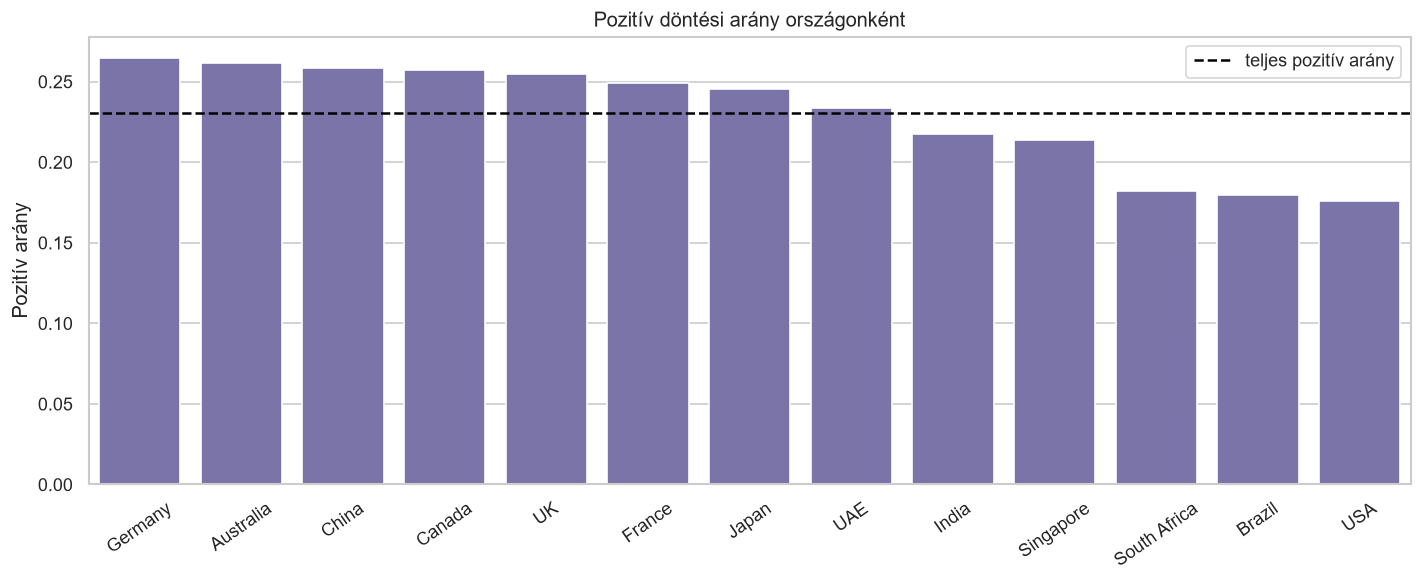

In [13]:
rate_by_country = (
    df.groupby("country", observed=True)["decision"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(
    data=rate_by_country.reset_index(),
    x="country",
    y="mean",
    color="#756bb1",
    ax=ax,
)
ax.axhline(target_rate, color="black", linestyle="--", label="teljes pozitív arány")
ax.set_title("Pozitív döntési arány országonként")
ax.set_ylabel("Pozitív arány")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=35)
ax.legend()
plt.tight_layout()
plt.show()
display(rate_by_country.rename(columns={"mean": "positive_rate"}))


### 3. ábra: numerikus változók kapcsolata a céllal

A korreláció -1 és +1 közötti szám. A 0-hoz közeli érték gyenge lineáris
kapcsolatot jelez. A korreláció nem ugyanaz, mint a modell fontossága, és a
nemlineáris kapcsolatokat nem feltétlenül mutatja meg.

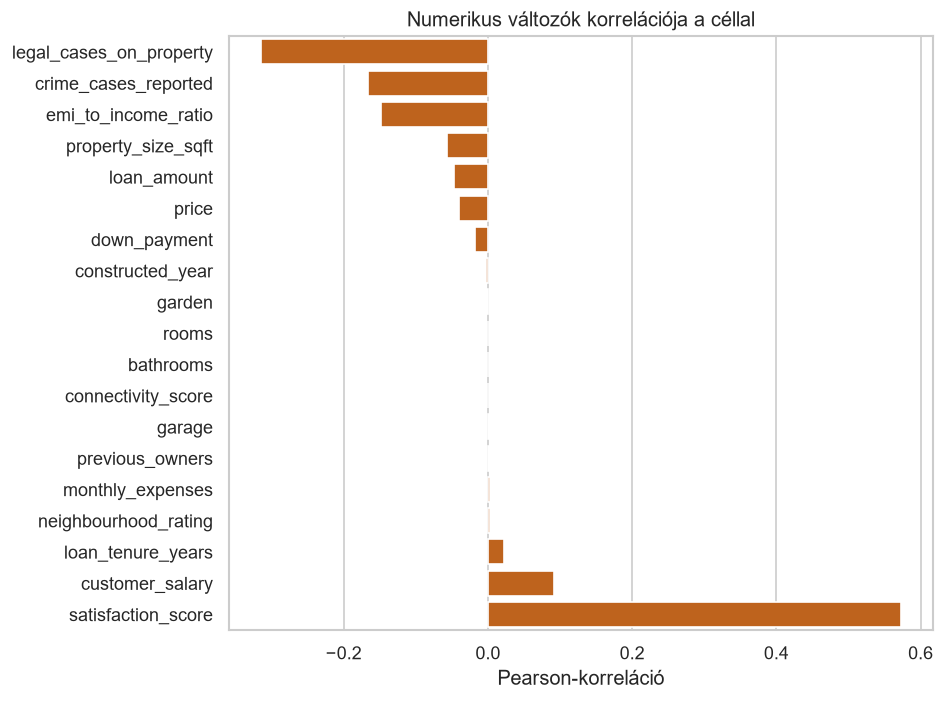

In [15]:
numeric_for_corr = df.select_dtypes(include=np.number).drop(columns=["property_id"])
corr = numeric_for_corr.corr(numeric_only=True)["decision"].drop("decision").sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=corr.values, y=corr.index, color="#d95f02", ax=ax)
ax.set_title("Numerikus változók korrelációja a céllal")
ax.set_xlabel("Pearson-korreláció")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


### 4. ábra: két változó együttes kapcsolata

A hőtérkép azt mutatja, hogy a `legal_cases_on_property` és a
`satisfaction_score` együttes értékei mellett mekkora a pozitív döntési arány.
Itt különösen erős, szabályos kapcsolat látszik. Ez szintetikus adatnál lehet
az adatgenerálás szabálya, valódi rendszerben pedig cél-szivárgási kockázat:
ha egy változó csak a döntés után ismert, nem szabadna bemenetként használni.

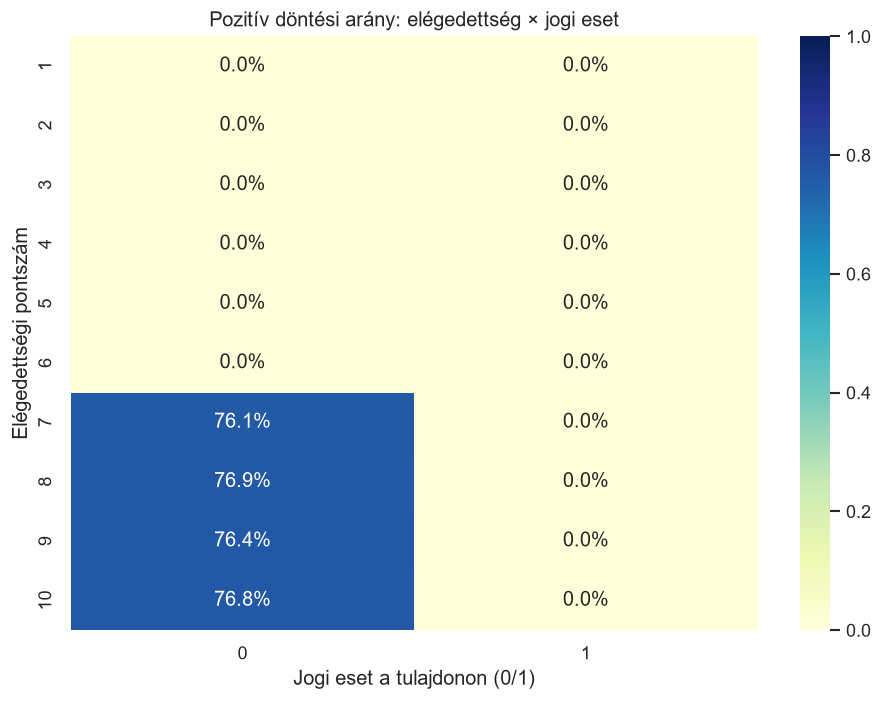

In [17]:
heatmap_data = pd.pivot_table(
    df,
    values="decision",
    index="satisfaction_score",
    columns="legal_cases_on_property",
    aggfunc="mean",
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".1%", cmap="YlGnBu", vmin=0, vmax=1, ax=ax)
ax.set_title("Pozitív döntési arány: elégedettség × jogi eset")
ax.set_xlabel("Jogi eset a tulajdonon (0/1)")
ax.set_ylabel("Elégedettségi pontszám")
plt.tight_layout()
plt.show()

### Szivárgásgyanús változók kizárása

Az EDA során két változó különösen erős, szabályos kapcsolatot mutatott a
`decision` célváltozóval: `satisfaction_score` és
`legal_cases_on_property`. Nem tudjuk biztosan, hogy ezek a változók a döntés
előtt rendelkezésre álltak-e, vagy a döntési folyamat részeként/utólag
keletkeztek. A biztonságosabb modell érdekében ebben a végső elemzésben
**kizárjuk mindkettőt**.

Ez szándékosan konzervatív döntés. Ha emiatt romlik a pontszám, az nem
feltétlenül kudarc: azt jelzi, hogy a modell kevésbé támaszkodik potenciálisan
szivárgó információra. A teljes modell és a szűkített modell eredményei így
nem keverednek össze; az alábbi ábrák és táblázatok már a szűkített modellből
származnak.

### Miért 80% tanító és 20% teszt?

Az arány nem önkényes: a tanár 04-klasszifikációs `demo.ipynb` példája is
`test_size=.2` beállítással használ 80% tanító és 20% teszt adatot, stratifikált
felosztással. Ezt a konvenciót követjük, így a tanító rész elég nagy marad a
modellek tanulásához és a cross-validationhöz, miközben a tesztben is marad
elég megfigyelés a végső, független ellenőrzéshez.

## 2. Tisztítás és a split

Hiányzó érték nincs, ezért imputálás várhatóan nem szükséges, de a pipeline-okban
szerepel, hogy a megoldás robusztus maradjon új adatok esetén. A CSV-ben az
`emi_to_income_ratio` 1760 értéke Excel-dátumként jelent meg (például
`03.jan`), holott a környezetében arányként szereplő `0.03` értéket jelenti.
Ezeket a nap-részt századdá alakítottuk, és az átalakítást dokumentáltuk.
Az
`property_id` csak azonosító, ezért elhagyjuk: az egyedi azonosító megtanulása
nem általánosítható. Az `emi_to_income_ratio` szöveges formátumát már a split
előtt numerikussá alakítottuk, ami nem adatból tanuló művelet.

A teszthalmazt most zároljuk. A későbbi modell- és feature-választás kizárólag
a tanító adaton történik. A tanító részen belül külön validációs halmazt
használunk a hangolás utáni, még nem látott ellenőrzéshez.


In [21]:
target = "decision"
suspicious_features = ["satisfaction_score", "legal_cases_on_property"]
drop_columns = ["property_id", target, *suspicious_features]
X = df.drop(columns=drop_columns)
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

X_dev, X_validation, y_dev, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=RANDOM_STATE,
)

print("Tanító:", X_train.shape, "Teszt:", X_test.shape)
print("Fejlesztési:", X_dev.shape, "Hangolási ellenőrzés:", X_validation.shape)
print(f"Teszt pozitív arány: {y_test.mean():.1%}")


Tanító: (160000, 21) Teszt: (40000, 21)
Fejlesztési: (120000, 21) Hangolási ellenőrzés: (40000, 21)
Teszt pozitív arány: 23.0%


## 3. Előkészítés és alapmodellek

### Miért próbálunk ki több modellt?

Nem tudjuk előre, hogy az adatokban egyszerű, egyenes vonallal leírható
kapcsolatok vannak-e, vagy inkább összetett szabályok és változó-kombinációk.
Ezért több különböző módszert hasonlítunk össze:

- **Dummy modell:** nem tanul valódi mintázatot, csak egy egyszerű referencia.
  Ennél egy használható modellnek jobbnak kell lennie.
- **Logisztikus regresszió:** lineáris modell. Jó baseline, gyors és könnyen
  értelmezhető, de főként additív, egyszerű kapcsolatokat tud kezelni.
- **Döntési fa:** szabályokat tanul, például „ha ez a változó nagyobb egy
  értéknél, akkor...”. Egyetlen fa könnyen túlilleszthető vagy instabil lehet.
- **Random Forest:** sok döntési fát tanít különböző mintákon és változókon,
  majd együtt szavaztatja őket. Emiatt általában stabilabb, és nemlineáris,
  több változót kombináló mintázatokat is megtalál.

Minden modellt ugyanazzal a három stratifikált cross-validation folddal
tesztelünk. Így nem az számít, hogy egy modell szerencsés adatrészt kapott-e,
hanem ugyanazon a feladaton hasonlítjuk össze őket.

In [24]:
categorical_features = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

numeric_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ]
)
categorical_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features),
    ]
)

def make_model(estimator, **params):
    return Pipeline(
        steps=[
            ("preprocess", preprocessor),
            ("model", estimator),
        ]
    )

models = {
    "dummy": make_model(DummyClassifier(strategy="prior", random_state=RANDOM_STATE)),
    "logistic_regression": make_model(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "decision_tree": make_model(
        DecisionTreeClassifier(
            max_depth=8,
            min_samples_leaf=20,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )
    ),
    "random_forest": make_model(
        RandomForestClassifier(
            n_estimators=180,
            min_samples_leaf=5,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )
    ),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)


### Hogyan döntjük el, melyik modell a jobb?

Fő mérőszámnak a **PR-AUC-t** választjuk, mert a célváltozó két osztálya nem
teljesen kiegyensúlyozott, és a pozitív találatok minősége fontos. A PR-AUC a
precision–recall görbe alatti terület: minél magasabb, annál jobban rangsorolja
a modell a pozitív eseteket.

Emellett megnézzük a balanced accuracy, precision és recall értékét is. Nem
csak a legnagyobb számot keressük: a szórás azt mutatja, mennyire stabil az
eredmény a különböző foldokon.

In [26]:
def cv_summary(model, X_data, y_data, cv_strategy=cv):
    scoring = {
        "pr_auc": "average_precision",
        "balanced_accuracy": "balanced_accuracy",
        "precision": "precision",
        "recall": "recall",
    }
    result = cross_validate(
        model,
        X_data,
        y_data,
        scoring=scoring,
        cv=cv_strategy,
        n_jobs=-1,
        return_train_score=False,
    )
    return {
        metric: (result[f"test_{metric}"].mean(), result[f"test_{metric}"].std())
        for metric in scoring
    }

model_rows = []
for name, model in models.items():
    summary = cv_summary(model, X_dev, y_dev)
    row = {"model": name}
    for metric, (mean, std) in summary.items():
        row[f"{metric}_mean"] = mean
        row[f"{metric}_std"] = std
    model_rows.append(row)

model_comparison = pd.DataFrame(model_rows).sort_values("pr_auc_mean", ascending=False)
display(model_comparison.style.format({
    "pr_auc_mean": "{:.3f}", "pr_auc_std": "{:.3f}",
    "balanced_accuracy_mean": "{:.3f}", "balanced_accuracy_std": "{:.3f}",
    "precision_mean": "{:.3f}", "precision_std": "{:.3f}",
    "recall_mean": "{:.3f}", "recall_std": "{:.3f}",
}))


,model,pr_auc_mean,pr_auc_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std
3,random_forest,0.304,0.002,0.521,0.001,0.308,0.004,0.125,0.004
2,decision_tree,0.301,0.002,0.649,0.001,0.300,0.000,0.987,0.001
1,logistic_regression,0.292,0.002,0.597,0.002,0.297,0.001,0.666,0.009
0,dummy,0.230,0.000,0.500,0.000,0.000,0.000,0.000,0.000


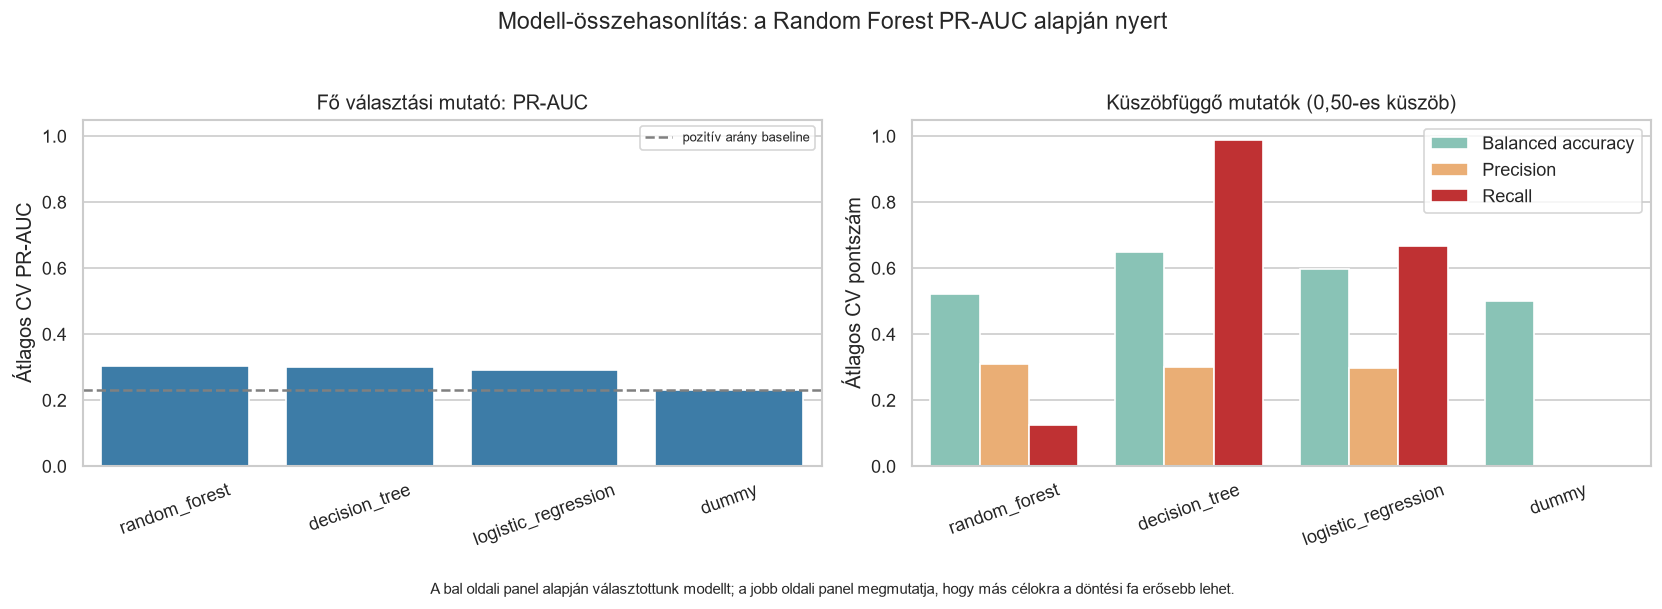

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ordered_models = model_comparison.sort_values("pr_auc_mean", ascending=False)["model"].tolist()
pr_auc_data = model_comparison.set_index("model").loc[ordered_models].reset_index()

sns.barplot(
    data=pr_auc_data,
    x="model",
    y="pr_auc_mean",
    color="#2c7fb8",
    ax=axes[0],
)
axes[0].set_title("Fő választási mutató: PR-AUC")
axes[0].set_xlabel("")
axes[0].set_ylabel("Átlagos CV PR-AUC")
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis="x", rotation=20)
axes[0].axhline(y=y_dev.mean(), color="gray", linestyle="--", label="pozitív arány baseline")
axes[0].legend(fontsize=8)

secondary_data = model_comparison.set_index("model").loc[ordered_models].reset_index().melt(
    id_vars="model",
    value_vars=["balanced_accuracy_mean", "precision_mean", "recall_mean"],
    var_name="metric",
    value_name="score",
)
secondary_data["metric"] = secondary_data["metric"].map(
    {
        "balanced_accuracy_mean": "Balanced accuracy",
        "precision_mean": "Precision",
        "recall_mean": "Recall",
    }
)
sns.barplot(
    data=secondary_data,
    x="model",
    y="score",
    hue="metric",
    palette=["#7fcdbb", "#fdae61", "#d7191c"],
    ax=axes[1],
)
axes[1].set_title("Küszöbfüggő mutatók (0,50-es küszöb)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Átlagos CV pontszám")
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(title="")

fig.suptitle(
    "Modell-összehasonlítás: a Random Forest PR-AUC alapján nyert",
    fontsize=14,
)
fig.text(
    0.5,
    0.01,
    "A bal oldali panel alapján választottunk modellt; a jobb oldali panel "
    "megmutatja, hogy más célokra a döntési fa erősebb lehet.",
    ha="center",
    fontsize=9,
)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()


### Miért a Random Forest lett a végső modell?

A modelleket ugyanazon tanító adaton, ugyanazokkal a keresztvalidációs foldokkal
hasonlítottuk össze. A fő választási mutató a **PR-AUC** volt, mert a pozitív
osztály kisebbségben van, és ez a mutató azt méri, mennyire jól rangsorolja a
modell a valóban pozitív eseteket.

Az ábra két külön kérdést mutat:

- **Bal panel – PR-AUC:** ebben a Random Forest lett a legjobb
  (`0,304`), ezért ezt választottuk a rangsorolási feladatra.
- **Jobb panel – 0,50-es döntési küszöb:** itt a döntési fa balanced
  accuracyban és recallban erősebb. Ez fontos lehet például egy ingatlanügynök
  számára, ha az elsődleges cél minél több pozitív lehetőség megtalálása.

Ezért nem azt állítjuk, hogy a Random Forest minden mutatóban első. A pontos
állítás az, hogy a Random Forest **a projekt fő mutatójában, a PR-AUC-ban**
teljesített a legjobban, miközben a döntési fa más célokra kedvezőbb lehet.
A végső Random Forest mellett szól az is, hogy a feature engineering és a
hangolás után a validációs PR-AUC nem romlott, és a modell stabil, jól
értelmezhető összehasonlítási alapot adott.

**Adatminőségi óvatosság:** a közel tökéletes eredmény nem jelenti automatikusan,
hogy a modell valódi lakáspiaci környezetben is tökéletes lesz. Az EDA során
erős, szabályos kapcsolatot láttunk néhány bemeneti változó és a cél között.
Ez lehet a szintetikus dataset generálási szabálya, vagy valódi használatban
akár cél-szivárgás jele is lehet.

In [29]:
best_baseline_name = model_comparison.iloc[0]["model"]
best_baseline = models[best_baseline_name]

oof_prob = cross_val_predict(
    best_baseline,
    X_dev,
    y_dev,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

print(f"CV-ben legjobb alapmodell: {best_baseline_name}")
print(f"OOF PR-AUC: {average_precision_score(y_dev, oof_prob):.3f}")


CV-ben legjobb alapmodell: random_forest
OOF PR-AUC: 0.304


## 4. Visszacsatolási kör: új, két változóból képzett jellemzők

Az EDA alapján azt a hipotézist teszteljük, hogy a puszta ár vagy hitelösszeg
helyett az arányok írják le jobban a pénzügyi terhelést. A feature engineering
nem használja a célváltozót, ezért minden foldban ugyanúgy reprodukálható.
Az összehasonlítást ugyanazokkal a foldokkal végezzük, így a páros különbség
értelmezhetőbb, mint két különböző felosztás eredménye.


In [31]:
def add_engineered_features(data):
    result = data.copy()
    eps = 1e-9
    result["price_per_sqft"] = result["price"] / result["property_size_sqft"].clip(lower=eps)
    result["loan_to_price"] = result["loan_amount"] / result["price"].clip(lower=eps)
    result["down_payment_to_price"] = result["down_payment"] / result["price"].clip(lower=eps)
    result["expenses_to_salary"] = result["monthly_expenses"] / result["customer_salary"].clip(lower=eps)
    result["down_payment_share_of_finance"] = result["down_payment"] / (
        result["down_payment"] + result["loan_amount"]
    ).clip(lower=eps)
    rating_columns = ["neighbourhood_rating", "connectivity_score"]
    result["ratings_mean"] = result[rating_columns].mean(axis=1)
    return result.replace([np.inf, -np.inf], np.nan)

X_dev_fe = add_engineered_features(X_dev)
X_validation_fe = add_engineered_features(X_validation)
X_train_fe = add_engineered_features(X_train)
X_test_fe = add_engineered_features(X_test)

numeric_features_fe = X_dev_fe.select_dtypes(include=np.number).columns.tolist()
categorical_features_fe = X_dev_fe.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()
preprocessor_fe = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features_fe),
        ("categorical", categorical_preprocessor, categorical_features_fe),
    ]
)

def make_fe_model(estimator):
    return Pipeline(steps=[("preprocess", preprocessor_fe), ("model", estimator)])

fe_models = {
    "logistic_regression_fe": make_fe_model(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "random_forest_fe": make_fe_model(
        RandomForestClassifier(
            n_estimators=180,
            min_samples_leaf=5,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )
    ),
}

fe_rows = []
for name, model in fe_models.items():
    summary = cv_summary(model, X_dev_fe, y_dev)
    row = {"model": name}
    for metric, (mean, std) in summary.items():
        row[f"{metric}_mean"] = mean
        row[f"{metric}_std"] = std
    fe_rows.append(row)

fe_comparison = pd.DataFrame(fe_rows).sort_values("pr_auc_mean", ascending=False)
display(fe_comparison.round(3))


,model,pr_auc_mean,pr_auc_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std
1,random_forest_fe,0.300,0.003,0.510,0.001,0.296,0.009,0.068,0.001
0,logistic_regression_fe,0.292,0.002,0.597,0.003,0.297,0.001,0.666,0.009


In [32]:
base_oof = cross_val_predict(
    models["random_forest"],
    X_dev,
    y_dev,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]
fe_oof = cross_val_predict(
    fe_models["random_forest_fe"],
    X_dev_fe,
    y_dev,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

paired_difference = average_precision_score(y_dev, fe_oof) - average_precision_score(y_dev, base_oof)
print(f"Random Forest feature engineering páros OOF PR-AUC különbsége: {paired_difference:+.3f}")
print("A különbség akkor meggyőző, ha a foldonkénti eredmények szórásához képest is érdemi.")

fold_differences = []
for fold_number, (train_idx, valid_idx) in enumerate(cv.split(X_dev, y_dev), start=1):
    base_fold = models["random_forest"].fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
    fe_fold = fe_models["random_forest_fe"].fit(X_dev_fe.iloc[train_idx], y_dev.iloc[train_idx])
    base_score = average_precision_score(
        y_dev.iloc[valid_idx],
        base_fold.predict_proba(X_dev.iloc[valid_idx])[:, 1],
    )
    fe_score = average_precision_score(
        y_dev.iloc[valid_idx],
        fe_fold.predict_proba(X_dev_fe.iloc[valid_idx])[:, 1],
    )
    fold_differences.append(
        {"fold": fold_number, "base_pr_auc": base_score, "fe_pr_auc": fe_score, "difference": fe_score - base_score}
    )
fold_difference_table = pd.DataFrame(fold_differences)
display(fold_difference_table.round(3))
print(
    "Páros különbség átlag ± szórás: "
    f"{fold_difference_table['difference'].mean():+.3f} ± "
    f"{fold_difference_table['difference'].std(ddof=1):.3f}"
)


Random Forest feature engineering páros OOF PR-AUC különbsége: -0.004
A különbség akkor meggyőző, ha a foldonkénti eredmények szórásához képest is érdemi.
Páros különbség átlag ± szórás: -0.003 ± 0.002


,fold,base_pr_auc,fe_pr_auc,difference
0,1,0.301,0.296,-0.005
1,2,0.307,0.302,-0.004
2,3,0.304,0.303,-0.001


## 5. Hangolás csak a fejlesztési adaton

In [34]:
rf_search = RandomizedSearchCV(
    estimator=fe_models["random_forest_fe"],
    param_distributions={
        "model__n_estimators": [60, 90, 120],
        "model__max_depth": [None, 8, 12, 18],
        "model__min_samples_leaf": [2, 5, 10, 20],
        "model__max_features": ["sqrt", 0.5],
    },
    n_iter=3,
    scoring="average_precision",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
)
rf_search.fit(X_dev_fe, y_dev)
print("Legjobb paraméterek:")
print(rf_search.best_params_)
print(f"Fejlesztési CV PR-AUC: {rf_search.best_score_:.3f}")


Legjobb paraméterek:
{'model__n_estimators': 120, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': 18}
Fejlesztési CV PR-AUC: 0.302


In [35]:
validation_models = {
    "baseline_random_forest": models["random_forest"],
    "tuned_random_forest_fe": rf_search.best_estimator_,
}
validation_rows = []
for name, model in validation_models.items():
    if name == "tuned_random_forest_fe":
        model.fit(X_dev_fe, y_dev)
        probabilities = model.predict_proba(X_validation_fe)[:, 1]
    else:
        model.fit(X_dev, y_dev)
        probabilities = model.predict_proba(X_validation)[:, 1]
    validation_rows.append(
        {
            "model": name,
            "validation_pr_auc": average_precision_score(y_validation, probabilities),
        }
    )

validation_comparison = pd.DataFrame(validation_rows).sort_values(
    "validation_pr_auc", ascending=False
)
display(validation_comparison.round(3))
selected_model_name = validation_comparison.iloc[0]["model"]
print(f"Előre nem látott validációs adaton kiválasztva: {selected_model_name}")


Előre nem látott validációs adaton kiválasztva: tuned_random_forest_fe


,model,validation_pr_auc
1,tuned_random_forest_fe,0.303
0,baseline_random_forest,0.303


## 6. Küszöb kiválasztása a tanító OOF-jóslataiból

A PR-AUC küszöbfüggetlen mutató. A végső osztálycímkéhez viszont kell küszöb.
Üzleti költség hiányában nem a tesztadatból választunk, hanem a teljes tanító
halmazon készített out-of-fold jóslatok balanced accuracy maximumát keressük.


Rögzített küszöb a záró teszthez: 0.330


,threshold,balanced_accuracy,precision,recall
56,0.330,0.653373,0.301677,0.998372
54,0.320,0.653337,0.301624,0.998698
55,0.325,0.653336,0.301647,0.998453
48,0.290,0.653327,0.301540,0.999539
53,0.315,0.653318,0.301603,0.998806


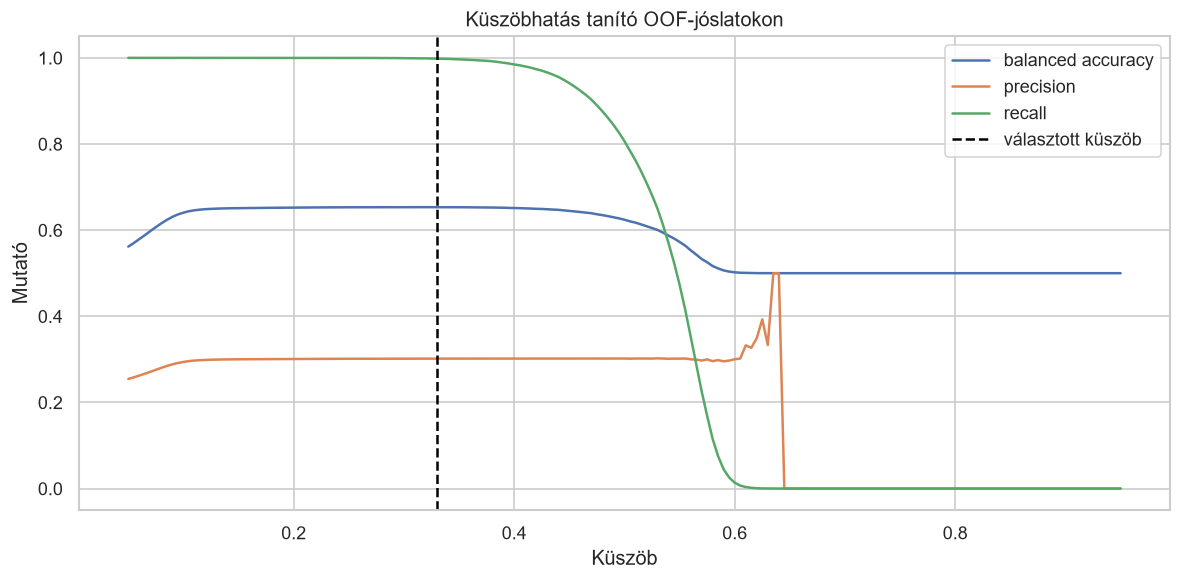

In [37]:
final_model_template = rf_search.best_estimator_ if selected_model_name == "tuned_random_forest_fe" else models["random_forest"]
X_train_for_model = X_train_fe if selected_model_name == "tuned_random_forest_fe" else X_train
X_dev_for_model = X_dev_fe if selected_model_name == "tuned_random_forest_fe" else X_dev
X_test_for_model = X_test_fe if selected_model_name == "tuned_random_forest_fe" else X_test

train_oof_prob = cross_val_predict(
    final_model_template,
    X_train_for_model,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

thresholds = np.linspace(0.05, 0.95, 181)
threshold_rows = [
    {
        "threshold": threshold,
        "balanced_accuracy": balanced_accuracy_score(y_train, train_oof_prob >= threshold),
        "precision": precision_score(y_train, train_oof_prob >= threshold, zero_division=0),
        "recall": recall_score(y_train, train_oof_prob >= threshold, zero_division=0),
    }
    for threshold in thresholds
]
threshold_table = pd.DataFrame(threshold_rows)
chosen_threshold = float(
    threshold_table.loc[
        threshold_table["balanced_accuracy"].idxmax(), "threshold"
    ]
)
print(f"Rögzített küszöb a záró teszthez: {chosen_threshold:.3f}")
display(threshold_table.sort_values("balanced_accuracy", ascending=False).head())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(threshold_table["threshold"], threshold_table["balanced_accuracy"], label="balanced accuracy")
ax.plot(threshold_table["threshold"], threshold_table["precision"], label="precision")
ax.plot(threshold_table["threshold"], threshold_table["recall"], label="recall")
ax.axvline(chosen_threshold, color="black", linestyle="--", label="választott küszöb")
ax.set_title("Küszöbhatás tanító OOF-jóslatokon")
ax.set_xlabel("Küszöb")
ax.set_ylabel("Mutató")
ax.legend()
plt.tight_layout()
plt.show()


### Precision és recall: két különböző felhasználói nézőpont

Egy modellnél nem elég azt megkérdezni, hogy hány jóslata lett helyes. Külön
érdekes, hogy **mennyire bízhatunk egy pozitív jelzésben**, illetve hogy
**mennyi valódi pozitív esetet talál meg**:

- **Precision (pontosság a pozitív jelzések között):** a pozitívnak jelzett
  lakások mekkora része valóban pozitív. Ez egy lakáskereső magánszemélynek
  lehet fontos: ha a modell érdekesnek jelöl egy lakást, minél ritkábban
  szeretnénk téves ajánlást kapni.
- **Recall (teljesség):** az összes valóban pozitív lakás mekkora részét találja
  meg a modell. Ez egy ingatlanügynöknek lehet fontos: minél kevesebb értékes
  lehetőséget szeretne kihagyni.

A két mutató között általában kompromisszum van. A döntési küszöb csökkentése
általában növeli a recallt, de több téves pozitív jelzést is okozhat, így a
precision csökkenhet. A megfelelő küszöböt ezért a felhasználási célhoz kell
igazítani, nem kizárólag egy általános pontszám alapján kiválasztani.

## 7. Záró teszt — pontosan egyszer

### Precision–recall görbe

A görbe minden lehetséges döntési küszöbnél megmutatja a precision és recall
közötti kompromisszumot. A görbe jobb felső része kedvezőbb: ott egyszerre
magas a pozitív jelzések megbízhatósága és a megtalált pozitív esetek aránya.

**Gyakorlati használat:**

- a magánszemély számára a görbén olyan küszöböt kereshetünk, ahol a precision
  magas;
- az ingatlanügynök számára olyan küszöböt, ahol a recall magas, még akkor is,
  ha ehhez több téves jelzést kell átnéznie.

Az **AP/PR-AUC** a precision–recall görbe összefoglaló, küszöbtől független
mutatója. A végső döntési küszöb ettől még külön üzleti döntés.

Konfúziós mátrix:
              precision    recall  f1-score   support

           0      0.999     0.305     0.467     30786
           1      0.301     0.999     0.463      9214

    accuracy                          0.465     40000
   macro avg      0.650     0.652     0.465     40000
weighted avg      0.838     0.465     0.466     40000



,test_value
PR-AUC,0.303
balanced_accuracy,0.652
precision,0.301
recall,0.999
top_10_percent_precision,0.306


,jósolt 0,jósolt 1
valós 0,9393,21393
valós 1,7,9207


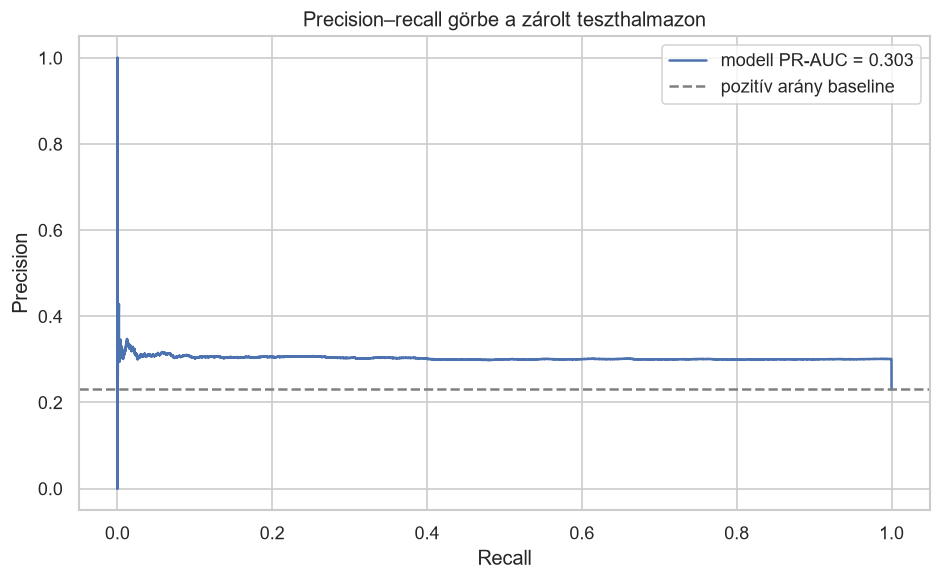

In [41]:
final_model = final_model_template.fit(X_train_for_model, y_train)
test_prob = final_model.predict_proba(X_test_for_model)[:, 1]
test_pred = (test_prob >= chosen_threshold).astype(int)

test_metrics = {
    "PR-AUC": average_precision_score(y_test, test_prob),
    "balanced_accuracy": balanced_accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "recall": recall_score(y_test, test_pred, zero_division=0),
}
top_fraction = 0.10
top_n = int(len(test_prob) * top_fraction)
top_risk_precision = y_test.iloc[np.argsort(-test_prob)[:top_n]].mean()
test_metrics["top_10_percent_precision"] = top_risk_precision
display(pd.Series(test_metrics, name="test_value").to_frame().round(3))

print("Konfúziós mátrix:")
display(
    pd.DataFrame(
        confusion_matrix(y_test, test_pred),
        index=["valós 0", "valós 1"],
        columns=["jósolt 0", "jósolt 1"],
    )
)
print(classification_report(y_test, test_pred, digits=3, zero_division=0))

precision_curve, recall_curve, curve_thresholds = precision_recall_curve(y_test, test_prob)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(recall_curve, precision_curve, label=f"modell PR-AUC = {test_metrics['PR-AUC']:.3f}")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label="pozitív arány baseline")
ax.set_title("Precision–recall görbe a zárolt teszthalmazon")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
plt.tight_layout()
plt.show()


In [42]:
def threshold_metrics(probabilities, true_labels, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "küszöb": threshold,
        "precision": precision_score(true_labels, predictions, zero_division=0),
        "recall": recall_score(true_labels, predictions, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(true_labels, predictions),
    }


persona_thresholds = pd.DataFrame(
    [
        threshold_metrics(test_prob, y_test, 0.50),
        threshold_metrics(test_prob, y_test, chosen_threshold),
    ],
    index=["általános 0.50-es küszöb", "tanító OOF alapján választott küszöb"],
)
display(persona_thresholds.round(3))

,küszöb,precision,recall,balanced_accuracy
általános 0.50-es küszöb,0.50,0.300,0.853,0.629
tanító OOF alapján választott küszöb,0.33,0.301,0.999,0.652


In [43]:
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_scores = []
positive_indices = np.flatnonzero(y_test.to_numpy() == 1)
negative_indices = np.flatnonzero(y_test.to_numpy() == 0)

for _ in range(300):
    sample_indices = rng.integers(0, len(y_test), len(y_test))
    sample_y = y_test.to_numpy()[sample_indices]
    if sample_y.min() == sample_y.max():
        continue
    bootstrap_scores.append(
        average_precision_score(sample_y, test_prob[sample_indices])
    )

ci_low, ci_high = np.percentile(bootstrap_scores, [2.5, 97.5])
print(
    f"Teszt PR-AUC bootstrap 95%-os konfidenciaintervalluma: "
    f"{test_metrics['PR-AUC']:.3f} [{ci_low:.3f}, {ci_high:.3f}]"
)


Teszt PR-AUC bootstrap 95%-os konfidenciaintervalluma: 0.303 [0.295, 0.311]


## 8. Saját lakás döntésének előrejelzése

Ez a notebook gyakorlati része. Az előző fejezetekben a modell megtanulta az
adatokban található mintázatokat. Most egy új, egyetlen lakásról szóló sort
adunk neki.

A következő cellában az `input_data` szótár értékeit átírhatod. A kulcsok nevei
maradjanak változatlanok, az értékeket viszont cseréld a saját adataidra.
`decision` mezőt nem kell megadni, mert éppen ezt jósoljuk meg. A
`property_id` sem kell, mert az csak azonosító.

In [45]:
# Ezt a példát írd át a saját adataidra.
input_data = {
    "country": "France",
    "city": "Marseille",
    "property_type": "Apartment",
    "furnishing_status": "Fully-Furnished",
    "property_size_sqft": 1500,
    "price": 500000,
    "constructed_year": 2010,
    "previous_owners": 2,
    "rooms": 4,
    "bathrooms": 2,
    "garage": 1,
    "garden": 1,
    "crime_cases_reported": 1,
    "customer_salary": 45000,
    "loan_amount": 300000,
    "loan_tenure_years": 20,
    "monthly_expenses": 7000,
    "down_payment": 200000,
    "emi_to_income_ratio": 0.18,
    "neighbourhood_rating": 7,
    "connectivity_score": 8,
}


def predict_new_house(values):
    expected_columns = list(X.columns)
    missing_columns = sorted(set(expected_columns) - set(values))
    extra_columns = sorted(set(values) - set(expected_columns))
    if missing_columns:
        raise ValueError(f"Hiányzó mezők: {missing_columns}")
    if extra_columns:
        raise ValueError(f"Ismeretlen mezők: {extra_columns}")

    new_row = pd.DataFrame([values], columns=expected_columns)
    if selected_model_name == "tuned_random_forest_fe":
        new_row = add_engineered_features(new_row)

    probability = float(final_model.predict_proba(new_row)[0, 1])
    prediction = int(probability >= chosen_threshold)
    return pd.DataFrame(
        {
            "eredmény": [
                "pozitív (decision=1)" if prediction else "negatív (decision=0)"
            ],
            "pozitív_valószínűség": [probability],
            "használt_küszöb": [chosen_threshold],
        }
    )


prediction_result = predict_new_house(input_data)
display(prediction_result)

,eredmény,pozitív_valószínűség,használt_küszöb
0,pozitív (decision=1),0.572913,0.33


### A jóslat értelmezése

- A **pozitív valószínűség** azt mutatja, mennyire tartja valószínűnek a modell
  a `decision = 1` kategóriát.
- A **használt küszöb** fölött a program pozitív, alatta negatív eredményt ad.
- A valószínűség nem garancia: a modell csak a tanító adatokban talált
  mintázatok alapján becsül.

## 9. Korlátok

1. A `decision` változó jelentése és a kétféle hiba valós pénzügyi költsége
   nincs részletesen megadva, ezért a küszöb csak módszertani választás, nem
   végleges üzleti döntés.
2. A célváltozó több bemeneti változóval nagyon erős, szabályos kapcsolatot
   mutat (például a jogi esetek és az elégedettségi pontszám kombinációja).
   Ez lehet a szintetikus adat generálásának szabálya, de ha ilyen változók a
   döntés után keletkeztek, akkor éles környezetben cél-szivárgást jelentenének.
3. A véletlenszerű, rétegzett split feltételezi, hogy a jövőbeli adatok
   hasonló eloszlásúak; időbeli vagy országonkénti eltolódás esetén az eredmény
   optimista lehet.
4. A dataset egyetlen forrásból származik, ezért a jó tesztmutató nem bizonyítja
   a más országokra, időszakokra vagy más adatgyűjtési folyamatokra való
   általánosíthatóságot.

## Összegzés

A végső modellt nem a tesztpontszám alapján választottuk. A döntés a tanító
adatok CV-eredményeire és az elkülönített validációra épült, a teszthalmazt
pedig csak egyszer, a végső becsléshez használtuk fel. A notebook minden
adatból tanuló lépése pipeline-ban fut, így az imputálás, skálázás és one-hot
kódolás nem szivárog át a validációs vagy tesztadatból.
